# Model 2073 — SVIX and Synthetic SVXY −1x

#### **MScFE 690 Capstone -Group 17843**

**Authors**: Edgar NAVA-edgar.nava@grovewm.com & Celestin NYANDWI-celestinnyandwi48@gmail.com

Compare Model 2073 on SVIX, buy and hold SVIX, and Model 2073 on synthetic SVXY −1x. Each period produces one performance table and one equity chart with three curves.

## 1. Settings

Use the unchanged rules from `08-Model_2073_SVXY-ONEx.ipynb`. Every account starts with $100,000 in cash. Costs are $0.005 per share and 0.10% adverse slippage per side. Fractional shares are allowed; cash earns no interest. Signals, trades and valuation use the same Close convention as Notebook 08. There is no forced final sale.

Both instruments use the same dates: **2 January 2024–16 September 2026** for Test and **30 March 2022–16 September 2026** for the full available SVIX history. The two periods are separate runs with fresh accounts. Use the raw VIX and SVIX CSVs and the processed synthetic SVXY −1x CSV in the directories set by `config.json`. Run all cells in order.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

%matplotlib inline

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from within the project folder.")
CONFIG = json.loads((PROJECT_ROOT / "config.json").read_text(encoding="utf-8"))
RAW_DATA_DIR = PROJECT_ROOT / CONFIG["raw_data_dir"]
PROCESSED_DATA_DIR = PROJECT_ROOT / CONFIG["processed_data_dir"]
RESULTS_DIR = Path.cwd() / "Results"
RESULTS_DIR.mkdir(exist_ok=True)
INITIAL_CASH = 100_000.0
COMMISSION_PER_SHARE = 0.005
SLIPPAGE_PCT = 0.001
SESSIONS_PER_YEAR = 252
ANNUAL_RISK_FREE_RATE = 0.0
STATE_THRESHOLDS = [17.5, 22.540001, 28.805999000000003, 37.810001]
DATA_CUTOFF = pd.Timestamp("2026-09-16")
PERIODS = {
    "Test": ("2024-01-02", "2026-09-16"),
    "Full history": ("2022-03-30", "2026-09-16"),
}
RULES = {
    "C2": {"vix_min": 23.0, "cash_fraction": 0.15,
           "target_nav": 0.70, "trailing_stop_pct": 0.20},
    "C3": {"vix_max": 28.0, "cash_fraction": 0.10,
           "invested_cash_fraction": 0.50, "trailing_stop_pct": 0.40},
    "V2": {"vix_min": 19.0},
    "V3": {"vix_max": 15.0},
}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "figure.dpi": 120,
})

def blue_table(frame, caption, formatter=None):
    return (frame.style.format(formatter, na_rep="N/A")
        .set_caption(caption)
        .set_table_styles([
            {"selector": "caption", "props": [("text-align", "left"),
                ("color", "#255c80"), ("font-size", "16px"), ("padding", "8px 0")]},
            {"selector": "th", "props": [("background-color", "#255c80"),
                ("color", "white"), ("text-align", "left"), ("padding", "9px 12px")]},
            {"selector": "td", "props": [("padding", "9px 12px"), ("text-align", "right")]},
            {"selector": "tbody tr:nth-child(even)",
             "props": [("background-color", "#edf3f7")]},
            {"selector": "table", "props": [("border-collapse", "collapse")]},
        ]))

## 2. Load the data

Use observed SVIX Close and the project’s synthetic SVXY −1x Close. Calculate VIX states and the preceding state before selecting the evaluation periods. No prices are filled or interpolated.

In [2]:
def read_close(path):
    frame = (pd.read_csv(path, parse_dates=["Date"])
             .set_index("Date").sort_index().loc[:DATA_CUTOFF, ["Close"]])
    if (frame.empty or not frame.index.is_unique or frame.index.hasnans
            or not np.isfinite(frame.Close).all() or not frame.Close.gt(0).all()):
        raise ValueError(f"Check dates and closing prices in {path}.")
    return frame

vix = read_close(RAW_DATA_DIR / "VIX_data.csv")
svix = read_close(RAW_DATA_DIR / "SVIX_data.csv")
svxy = read_close(PROCESSED_DATA_DIR / "SVXY_synth-ONEx.csv")
vix["State"] = np.searchsorted(STATE_THRESHOLDS, vix.Close.to_numpy(), side="left") + 1
vix["Previous_state"] = vix.State.shift(1)
signals = vix.rename(columns={"Close": "VIX_Close"})
prices = {
    "SVIX": svix.join(signals, how="left"),
    "SVXY −1x": svxy.join(signals, how="left"),
}
for label, (start, end) in PERIODS.items():
    left = prices["SVIX"].loc[start:end]
    right = prices["SVXY −1x"].loc[start:end]
    if (left.empty or left.index[0] != pd.Timestamp(start)
            or left.index[-1] != pd.Timestamp(end)
            or not left.index.equals(right.index)
            or left.isna().any().any() or right.isna().any().any()):
        raise ValueError(f"Incomplete or unmatched data for {label}.")


## 3. Model 2073 and results

C2 buys on S2→S3 with VIX >23; C3 buys on S4→S3 with VIX <28. Their trailing stops are 20% and 40%. V1, V2 and V3 retain the same exit rules and daily priority as Notebook 08. Each actual purchase resets the price peak and applies its stop to the whole position.

CAGR uses calendar days; Sharpe uses 252 sessions per year and a zero risk-free rate. Maximum drawdown is shown as a positive loss magnitude; Calmar equals CAGR divided by that magnitude. Full history includes 2022–2023 and is not a second independent out-of-sample test.

In [3]:
def finish_account(account):
    account = account.copy()
    account["Position_value"] = account.Units * account.Close
    account["Equity"] = account.Cash + account.Position_value
    account["Daily_return"] = account.Equity.pct_change(fill_method=None)
    account.loc[account.index[0], "Daily_return"] = account.Equity.iloc[0] / INITIAL_CASH - 1
    account["Drawdown"] = account.Equity / account.Equity.cummax().clip(lower=INITIAL_CASH) - 1
    account["Exposure"] = account.Position_value / account.Equity
    return account


def run_buy_and_hold(data):
    account = data[["Close"]].copy()
    first_close = float(account.Close.iloc[0])
    execution_price = first_close * (1 + SLIPPAGE_PCT)
    units = INITIAL_CASH / (execution_price + COMMISSION_PER_SHARE)
    account["Cash"], account["Units"] = 0.0, units
    account["Commission"], account["Slippage_cost"] = 0.0, 0.0
    account.loc[account.index[0], "Commission"] = units * COMMISSION_PER_SHARE
    account.loc[account.index[0], "Slippage_cost"] = units * first_close * SLIPPAGE_PCT
    return finish_account(account)


def performance(account):
    final = float(account.Equity.iloc[-1])
    years = (account.index[-1] - account.index[0]).days / 365.25
    cagr = (final / INITIAL_CASH) ** (1 / years) - 1
    max_drawdown = float(account.Drawdown.min())
    daily_rf = (1 + ANNUAL_RISK_FREE_RATE) ** (1 / SESSIONS_PER_YEAR) - 1
    excess = account.Daily_return - daily_rf
    volatility = float(excess.std(ddof=1))
    return pd.Series({
        "Initial equity ($)": INITIAL_CASH,
        "Final equity ($)": final,
        "Total profit ($)": final - INITIAL_CASH,
        "Total return": final / INITIAL_CASH - 1,
        "Annualized return (CAGR)": cagr,
        "Sharpe ratio": np.sqrt(SESSIONS_PER_YEAR) * excess.mean() / volatility
            if volatility > 0 else np.nan,
        "Calmar ratio": cagr / abs(max_drawdown)
            if np.isfinite(cagr) and max_drawdown < 0 else np.nan,
        "Drawdown at final date": float(account.Drawdown.iloc[-1]),
        "Maximum drawdown": max_drawdown,
    })

def run_model(data):
    cash, units, flag = INITIAL_CASH, 0.0, 0
    peak_close = active_stop_pct = np.nan
    records, orders = [], []
    cash_tolerance = max(1.0, INITIAL_CASH) * 1e-12

    for date, row in data.iterrows():
        price, vix_close = float(row.Close), float(row.VIX_Close)
        state, previous = int(row.State), int(row.Previous_state)
        equity_before = cash + units * price
        side, rule_id = None, ""
        target, execution_price = np.nan, np.nan
        commission, slippage_cost = 0.0, 0.0

        # Existing stops take priority over all other signals.
        if units > 0:
            peak_close = max(peak_close, price)
            if price <= peak_close * (1 - active_stop_pct):
                side, rule_id = "SELL", "V1"

        if side is None and units > 0:
            if state == 1 and previous in (2, 3, 4, 5):
                flag = 1
            if flag == 1:
                if previous == 1 and state > 1 and vix_close > RULES["V2"]["vix_min"]:
                    side, rule_id = "SELL", "V2"
                elif state == 1 and vix_close < RULES["V3"]["vix_max"]:
                    side, rule_id = "SELL", "V3"

        if side == "SELL":
            quantity = units
            execution_price = price * (1 - SLIPPAGE_PCT)
            commission = quantity * COMMISSION_PER_SHARE
            slippage_cost = quantity * price * SLIPPAGE_PCT
            cash += quantity * execution_price - commission
            units, flag = 0.0, 0
            peak_close = active_stop_pct = np.nan
        else:
            if previous == 2 and state == 3 and vix_close > RULES["C2"]["vix_min"]:
                rule_id = "C2"
                target = RULES[rule_id]["target_nav"] if units > 0 else RULES[rule_id]["cash_fraction"]
            elif previous == 4 and state == 3 and vix_close < RULES["C3"]["vix_max"]:
                rule_id = "C3"
                target = RULES[rule_id]["invested_cash_fraction"] if units > 0 else RULES[rule_id]["cash_fraction"]

            if np.isfinite(target):
                execution_price = price * (1 + SLIPPAGE_PCT)
                all_in_price = execution_price + COMMISSION_PER_SHARE
                if units == 0 or rule_id == "C3":
                    quantity = target * cash / all_in_price
                else:
                    # C2 targets position value / NAV after transaction costs.
                    gap = max(0.0, target * equity_before - units * price)
                    quantity = min(cash / all_in_price,
                        gap / (price + target * (price * SLIPPAGE_PCT + COMMISSION_PER_SHARE)))

                if quantity * all_in_price > cash_tolerance:
                    side = "BUY"
                    commission = quantity * COMMISSION_PER_SHARE
                    slippage_cost = quantity * price * SLIPPAGE_PCT
                    cash -= quantity * execution_price + commission
                    units += quantity
                    active_stop_pct = RULES[rule_id]["trailing_stop_pct"]
                    peak_close = price

        # Remove floating-point residue without allowing borrowing.
        if -cash_tolerance <= cash < 0:
            cash = 0.0
        if cash < 0 or units < 0:
            raise ArithmeticError(f"Negative cash or units at {date}.")
        if units == 0:
            flag = 0
        stop = peak_close * (1 - active_stop_pct) if units > 0 else np.nan

        if side is not None:
            orders.append({
                "Date": date, "Side": side, "Rule ID": rule_id,
                "Close": price, "Execution price": execution_price, "Units": quantity,
                "Commission ($)": commission, "Slippage ($)": slippage_cost,
                "Cash after": cash, "Units after": units,
            })
        records.append({
            "Date": date, "Close": price, "VIX_Close": vix_close,
            "State": state, "Previous_state": previous,
            "Cash": cash, "Units": units, "Commission": commission,
            "Slippage_cost": slippage_cost, "Peak_close": peak_close,
            "Stop_threshold": stop, "Trailing_stop_pct": active_stop_pct,
            "Flag": flag, "Action": side or "HOLD", "Rule ID": rule_id,
        })

    account = finish_account(pd.DataFrame(records).set_index("Date"))
    order_columns = ["Date", "Side", "Rule ID", "Close", "Execution price", "Units",
                     "Commission ($)", "Slippage ($)", "Cash after", "Units after"]
    return account, pd.DataFrame(orders, columns=order_columns)

In [4]:
results = {}

def show_results(label):
    start, end = PERIODS[label]
    svix_sample = prices["SVIX"].loc[start:end]
    svxy_sample = prices["SVXY −1x"].loc[start:end]
    svix_account, _ = run_model(svix_sample)
    svxy_account, _ = run_model(svxy_sample)
    accounts = {
        "2073 on SVIX": svix_account,
        "Buy and hold SVIX": run_buy_and_hold(svix_sample),
        "2073 on SVXY −1x": svxy_account,
    }
    metrics = pd.DataFrame({name: performance(frame) for name, frame in accounts.items()})
    rows = ["Initial equity ($)", "Final equity ($)", "Total return",
            "Annualized return (CAGR)", "Maximum drawdown", "Sharpe ratio", "Calmar ratio"]
    metrics = metrics.loc[rows].copy()
    metrics.loc["Maximum drawdown"] = metrics.loc["Maximum drawdown"].abs()
    metrics = metrics.rename(index={"Annualized return (CAGR)": "CAGR"})
    formatted = metrics.astype(object).copy()
    for metric in metrics.index:
        if "($)" in metric:
            formatted.loc[metric] = metrics.loc[metric].map(lambda x: f"${x:,.2f}")
        elif metric in ("Sharpe ratio", "Calmar ratio"):
            formatted.loc[metric] = metrics.loc[metric].map(lambda x: f"{x:.3f}")
        else:
            formatted.loc[metric] = metrics.loc[metric].map(lambda x: f"{x:.2%}")
    display(blue_table(formatted, f"{label}: {start} to {end} — results after costs"))

    fig, ax = plt.subplots(figsize=(11, 5))
    for (name, frame), color in zip(accounts.items(), ["#226a95", "#ce7b29", "#2b8069"]):
        ax.plot(frame.index, frame.Equity, label=name, color=color, linewidth=1.6)
    ax.set(xlabel="Date", ylabel="Equity ($)")
    fig.suptitle(f"{label} — Model 2073 and buy and hold", y=0.99)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=3,
              frameon=False, fontsize=10)
    ax.grid(alpha=0.18)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    slug = label.lower().replace(" ", "_")
    fig.savefig(RESULTS_DIR / f"{slug}_three_curves.png", dpi=180, bbox_inches="tight")
    metrics.to_csv(RESULTS_DIR / f"{slug}_comparison.csv")
    plt.show()
    results[label] = {"accounts": accounts, "metrics": metrics}


## 4. Test

,2073 on SVIX,Buy and hold SVIX,2073 on SVXY −1x
Initial equity ($),"$100,000.00","$100,000.00","$100,000.00"
Final equity ($),"$125,453.93","$72,702.66","$126,351.27"
Total return,25.45%,-27.30%,26.35%
CAGR,8.74%,-11.12%,9.03%
Maximum drawdown,22.13%,79.30%,22.35%
Sharpe ratio,0.552,0.202,0.552
Calmar ratio,0.395,-0.140,0.404


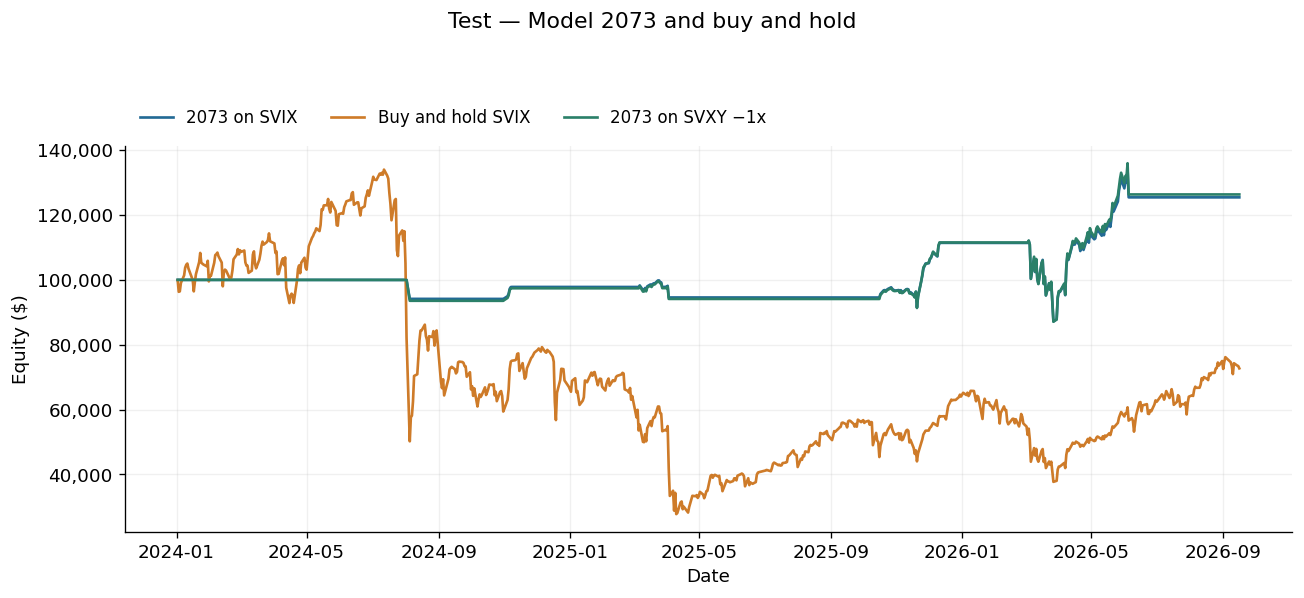

In [5]:
show_results("Test")

## 5. Full available SVIX history

,2073 on SVIX,Buy and hold SVIX,2073 on SVXY −1x
Initial equity ($),"$100,000.00","$100,000.00","$100,000.00"
Final equity ($),"$220,798.45","$185,823.03","$234,318.58"
Total return,120.80%,85.82%,134.32%
CAGR,19.41%,14.88%,21.01%
Maximum drawdown,24.38%,79.30%,24.24%
Sharpe ratio,0.838,0.559,0.876
Calmar ratio,0.796,0.188,0.867


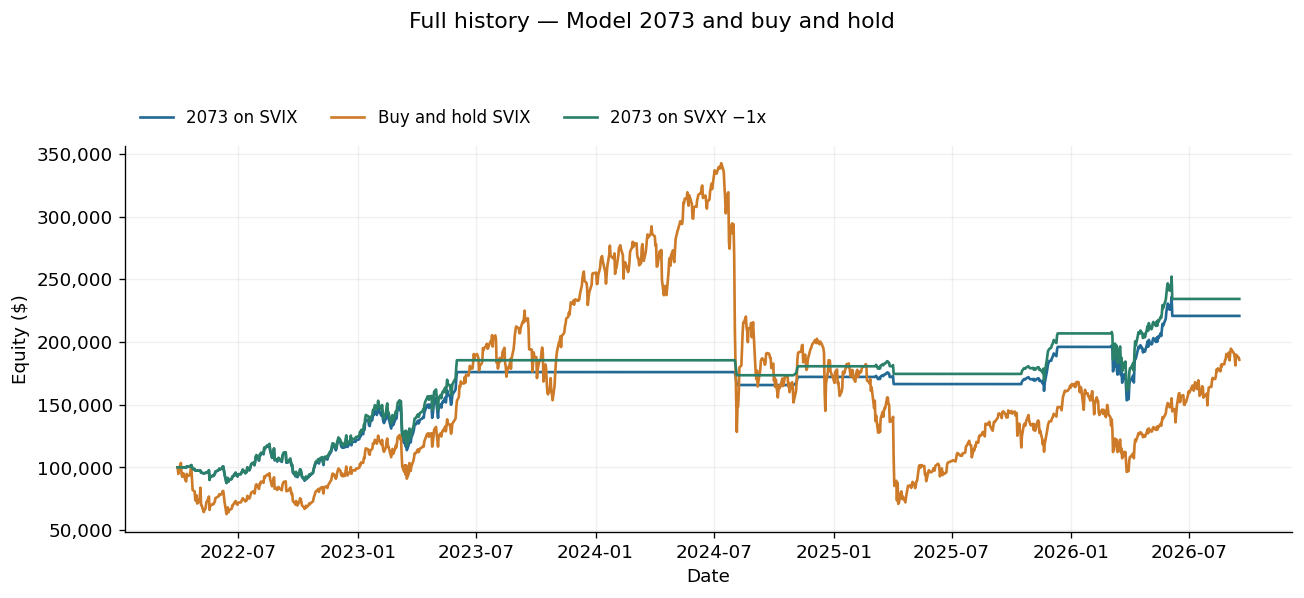

In [6]:
show_results("Full history")